In [16]:
# ── Cell 1: Check GPU ─────────────────────────────────────────────────────────
import torch
print('CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('Memory:', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), 'GB')

CUDA: True
GPU: Tesla T4
Memory: 15.6 GB


In [17]:
# ── Cell 2: Install deps ──────────────────────────────────────────────────────
!pip install -q scikit-learn

In [18]:
# ── Cell 3: Upload dataset ───────────────────────────────────────────────────
# OPTION A: Upload zip
from google.colab import files
uploaded = files.upload()   # select hackathon_dataset.zip

import zipfile, os
zip_name = list(uploaded.keys())[0]
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('.')

# Find the data root (handles nested zips)
import pathlib
roots = list(pathlib.Path('.').glob('**/train_metadata.csv'))
assert roots, 'train_metadata.csv not found after unzip'
DATA_DIR = str(roots[0].parent)
print('DATA_DIR =', DATA_DIR)

Saving hackathon_dataset (2).zip to hackathon_dataset (2) (1).zip
DATA_DIR = hackathon_dataset/hackathon_dataset


In [19]:
# ── Cell 4: Check native image sizes (decides if higher resolution is worth it) ─
import pandas as pd
from pathlib import Path
from PIL import Image

_meta = pd.read_csv(Path(DATA_DIR) / 'train_metadata.csv')
_rows = []
for _label, _sub in [(0, 'real'), (1, 'fake')]:
    _pool = _meta[_meta['label'] == _label]['image_id']
    for _i in _pool.sample(min(150, len(_pool)), random_state=0):
        _p = Path(DATA_DIR) / 'train' / _sub / f'{_i}.jpg'
        with Image.open(_p) as _im:
            _w, _h = _im.size
        _rows.append({'class': _sub, 'w': _w, 'h': _h, 'kb': _p.stat().st_size / 1024})
_s = pd.DataFrame(_rows)
print(_s.groupby('class').agg(['min', 'median', 'max']).round(1).to_string())
print()
print('How to read this:')
print(' - If w/h are well below IMAGE_SIZE (Cell 5), upscaling adds no detail: keep IMAGE_SIZE near the native size.')
print(' - If real and fake differ a lot in size or kb, the model may be using that as a shortcut.')

         w                h               kb             
       min median  max  min median  max  min median   max
class                                                    
fake   224  224.0  224  224  224.0  224  5.0   10.9  36.5
real   224  224.0  224  224  224.0  224  5.6   11.2  30.9

How to read this:
 - If w/h are well below IMAGE_SIZE (Cell 5), upscaling adds no detail: keep IMAGE_SIZE near the native size.
 - If real and fake differ a lot in size or kb, the model may be using that as a shortcut.


In [20]:
# ── Cell 5: Imports & config ──────────────────────────────────────────────────
import os, random, time
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b4, EfficientNet_B4_Weights

# ── Hyperparameters ───────────────────────────────────────────────────────────
IMAGE_SIZE   = 380      # 224 = v1 speed | 320 = ~2x cost | 380 = B4 native, ~2.9x cost
BATCH_SIZE   = 16       # 32 fits at 224; use 16 at 320/380 on a T4 (drop to 8 if OOM)
NUM_EPOCHS   = 12       # v1 peaked at epochs 5-8, so 12 is plenty
LR           = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS  = 2
SEED         = 42       # keep 42 + VAL_SPLIT 0.2 so the val set matches v1/v2
VAL_SPLIT    = 0.2
THRESHOLD    = 0.5
PATIENCE     = 4
USE_TUNED_THRESHOLD = False   # True = use the val-F1-optimal threshold for test predictions
DEVICE       = 'cuda' if torch.cuda.is_available() else 'cpu'
OUTPUT_DIR   = Path('./output_v3')
OUTPUT_DIR.mkdir(exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(SEED)
print(f'Device: {DEVICE}  |  Image size: {IMAGE_SIZE}  |  Batch: {BATCH_SIZE}  |  Output: {OUTPUT_DIR}')

Device: cuda  |  Image size: 380  |  Batch: 16  |  Output: output_v3


In [21]:
# ── Cell 6: Dataset classes ───────────────────────────────────────────────────
class DeepfakeDataset(Dataset):
    def __init__(self, df, data_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.data_dir = Path(data_dir)
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        label = int(row['label'])
        subdir = 'fake' if label == 1 else 'real'
        img_path = self.data_dir / 'train' / subdir / f"{row['image_id']}.jpg"
        img = Image.open(img_path).convert('RGB')
        if self.transform: img = self.transform(img)
        return img, torch.tensor(label, dtype=torch.float32)


class TestDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = Path(image_dir)
        self.image_paths = sorted(list(self.image_dir.glob('*.jpg')) +
                                   list(self.image_dir.glob('*.png')))
        self.transform = transform

    def __len__(self): return len(self.image_paths)

    def __getitem__(self, idx):
        p = self.image_paths[idx]
        img = Image.open(p).convert('RGB')
        if self.transform: img = self.transform(img)
        return img, p.stem

print('Dataset classes ready.')

Dataset classes ready.


In [22]:
# ── Cell 7: Transforms (v1's mild augmentation, no blur / mixup) ─────────────
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
    transforms.RandomErasing(p=0.1, scale=(0.02, 0.1)),
])

val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

print('Transforms ready.')

Transforms ready.


In [23]:
# ── Cell 8: Load data & split ─────────────────────────────────────────────────
metadata = pd.read_csv(Path(DATA_DIR) / 'train_metadata.csv')
print('Total samples:', len(metadata))
print(metadata['label'].value_counts())

train_df, val_df = train_test_split(
    metadata, test_size=VAL_SPLIT, stratify=metadata['label'], random_state=SEED
)

train_ds = DeepfakeDataset(train_df, DATA_DIR, train_transform)
val_ds   = DeepfakeDataset(val_df,   DATA_DIR, val_transform)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
print(f'Train: {len(train_df)}  |  Val: {len(val_df)}')

Total samples: 7000
label
1    3522
0    3478
Name: count, dtype: int64
Train: 5600  |  Val: 1400


In [24]:
# ── Cell 9: Model ─────────────────────────────────────────────────────────────
# Pretrained EfficientNet-B4 (ImageNet weights), new 1-logit head, all layers trained (as in v1)
model = efficientnet_b4(weights=EfficientNet_B4_Weights.IMAGENET1K_V1)
in_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, 1),
)
model = model.to(DEVICE)
print(f'Total params: {sum(p.numel() for p in model.parameters()):,}')

Total params: 17,550,409


In [25]:
# ── Cell 10: Train / validate functions ──────────────────────────────────────
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)
scaler    = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))

best_auc  = 0.0
best_path = OUTPUT_DIR / 'model_weights.pt'
history   = []

def train_epoch(model, loader):
    model.train()
    total_loss, all_labels, all_probs = 0.0, [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE).unsqueeze(1)
        optimizer.zero_grad()
        with torch.autocast(device_type='cuda', enabled=(DEVICE == 'cuda')):
            logits = model(imgs)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        total_loss += loss.item() * imgs.size(0)
        all_probs.extend(torch.sigmoid(logits).detach().float().cpu().numpy().flatten().tolist())
        all_labels.extend(labels.cpu().numpy().flatten().tolist())
    return total_loss / len(loader.dataset), roc_auc_score(all_labels, all_probs)

@torch.no_grad()
def validate_epoch(model, loader):
    model.eval()
    total_loss, all_labels, all_probs = 0.0, [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE).unsqueeze(1)
        with torch.autocast(device_type='cuda', enabled=(DEVICE == 'cuda')):
            logits = model(imgs)
            loss = criterion(logits, labels)
        total_loss += loss.item() * imgs.size(0)
        all_probs.extend(torch.sigmoid(logits).float().cpu().numpy().flatten().tolist())
        all_labels.extend(labels.cpu().numpy().flatten().tolist())
    auc = roc_auc_score(all_labels, all_probs)
    preds = (np.array(all_probs) >= THRESHOLD).astype(int)
    return total_loss / len(loader.dataset), auc, f1_score(all_labels, preds), accuracy_score(all_labels, preds)

print('Train/val functions ready.')

Train/val functions ready.


/tmp/ipykernel_387/2133834547.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))


In [26]:
# ── Cell 11: Training loop ────────────────────────────────────────────────────
cols = ['Epoch', 'TrLoss', 'TrAUC', 'VaLoss', 'VaAUC', 'F1', 'Acc']
print(''.join(f'{c:>9}' for c in cols))
print('-' * 70)

no_improve = 0
for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_auc = train_epoch(model, train_loader)
    va_loss, va_auc, va_f1, va_acc = validate_epoch(model, val_loader)
    scheduler.step()

    vals = [epoch, tr_loss, tr_auc, va_loss, va_auc, va_f1, va_acc]
    print(f'{epoch:>9}' + ''.join(f'{v:>9.4f}' for v in vals[1:]) + f'   ({time.time() - t0:.0f}s)')
    history.append({'epoch': epoch, 'tr_loss': tr_loss, 'tr_auc': tr_auc,
                    'va_loss': va_loss, 'va_auc': va_auc, 'va_f1': va_f1, 'va_acc': va_acc})

    if va_auc > best_auc:
        best_auc = va_auc
        torch.save(model.state_dict(), best_path)
        print(f'  ✓ Best AUC: {best_auc:.4f} — saved')
        no_improve = 0
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f'Early stopping at epoch {epoch}')
            break

pd.DataFrame(history).to_csv(OUTPUT_DIR / 'training_log.csv', index=False)
print()
print(f'✓ Best val AUC: {best_auc:.4f}   (v1: 0.8749 | v2: 0.8575)')

    Epoch   TrLoss    TrAUC   VaLoss    VaAUC       F1      Acc
----------------------------------------------------------------------
        1   0.6140   0.7387   0.5069   0.8427   0.8010   0.7736   (167s)
  ✓ Best AUC: 0.8427 — saved
        2   0.4573   0.8677   0.4518   0.8718   0.8291   0.8157   (149s)
  ✓ Best AUC: 0.8718 — saved
        3   0.3947   0.9013   0.4290   0.8819   0.8307   0.8314   (153s)
  ✓ Best AUC: 0.8819 — saved
        4   0.3484   0.9237   0.4322   0.8803   0.8438   0.8379   (144s)
        5   0.3212   0.9349   0.4327   0.8830   0.8435   0.8429   (145s)
  ✓ Best AUC: 0.8830 — saved
        6   0.2809   0.9507   0.4482   0.8797   0.8494   0.8450   (145s)
        7   0.2666   0.9554   0.4812   0.8797   0.8395   0.8400   (145s)
        8   0.2240   0.9689   0.4998   0.8735   0.8408   0.8386   (144s)
        9   0.2111   0.9722   0.5111   0.8747   0.8422   0.8386   (140s)
Early stopping at epoch 9

✓ Best val AUC: 0.8830   (v1: 0.8749 | v2: 0.8575)


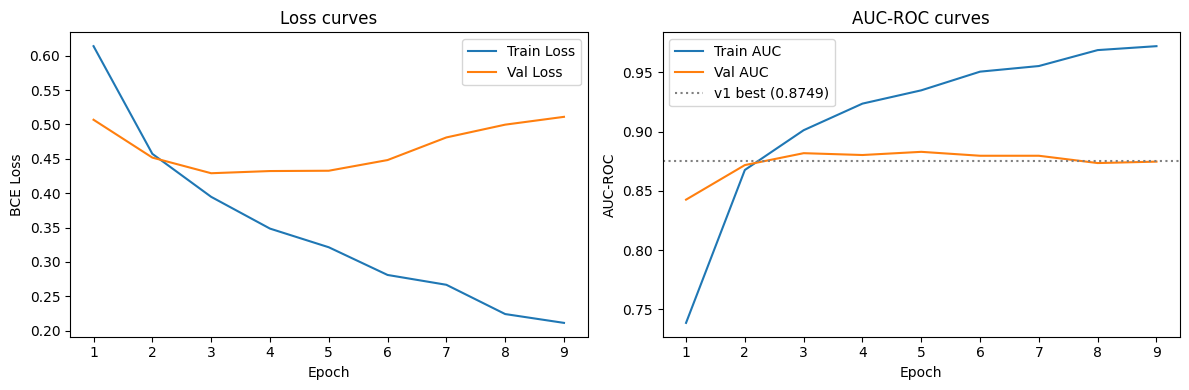

In [27]:
# ── Cell 12: Plot training curves ─────────────────────────────────────────────
import matplotlib.pyplot as plt

log = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(log['epoch'], log['tr_loss'], label='Train Loss')
axes[0].plot(log['epoch'], log['va_loss'], label='Val Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE Loss')
axes[0].set_title('Loss curves'); axes[0].legend()

axes[1].plot(log['epoch'], log['tr_auc'], label='Train AUC')
axes[1].plot(log['epoch'], log['va_auc'], label='Val AUC')
axes[1].axhline(0.8749, color='gray', linestyle=':', label='v1 best (0.8749)')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUC-ROC')
axes[1].set_title('AUC-ROC curves'); axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves_v3.png', dpi=150)
plt.show()

In [28]:
# ── Cell 13: Reload best checkpoint, test whether flip-TTA helps, tune threshold ─
model.load_state_dict(torch.load(best_path, map_location=DEVICE, weights_only=True))
model.eval()

@torch.no_grad()
def predict(loader, tta=False):
    probs_all, second = [], []
    for imgs, extra in loader:
        imgs = imgs.to(DEVICE)
        with torch.autocast(device_type='cuda', enabled=(DEVICE == 'cuda')):
            logits = model(imgs)
            if tta:
                logits = (logits.float() + model(torch.flip(imgs, dims=[3])).float()) / 2
        probs_all.extend(torch.sigmoid(logits.float()).squeeze(-1).cpu().numpy().tolist())
        second.extend(extra.tolist() if torch.is_tensor(extra) else list(extra))
    return np.array(probs_all), second

val_p0, val_y = predict(val_loader, tta=False)
val_p1, _     = predict(val_loader, tta=True)
val_y = np.array(val_y).astype(int)

auc0, auc1 = roc_auc_score(val_y, val_p0), roc_auc_score(val_y, val_p1)
print(f'Val AUC  no TTA: {auc0:.4f}  |  flip-TTA: {auc1:.4f}')
USE_TTA = auc1 > auc0
print('Using TTA for test predictions:', USE_TTA)
val_p = val_p1 if USE_TTA else val_p0

ths = np.arange(0.2, 0.81, 0.02)
f1s = [f1_score(val_y, (val_p >= t).astype(int)) for t in ths]
best_t = float(ths[int(np.argmax(f1s))])
f1_at_default = f1_score(val_y, (val_p >= THRESHOLD).astype(int))
acc_at_default = accuracy_score(val_y, (val_p >= THRESHOLD).astype(int))
print(f'@ threshold {THRESHOLD:.2f}: F1 {f1_at_default:.4f}  Acc {acc_at_default:.4f}')
print(f'Best-F1 threshold on val: {best_t:.2f}  (F1 {max(f1s):.4f})')
print('Note: tuning on the same val set used to pick the checkpoint is slightly optimistic.')
FINAL_THRESHOLD = best_t if USE_TUNED_THRESHOLD else THRESHOLD
print('Threshold used for test:', FINAL_THRESHOLD)

Val AUC  no TTA: 0.8830  |  flip-TTA: 0.8831
Using TTA for test predictions: True
@ threshold 0.50: F1 0.8389  Acc 0.8393
Best-F1 threshold on val: 0.36  (F1 0.8542)
Note: tuning on the same val set used to pick the checkpoint is slightly optimistic.
Threshold used for test: 0.5


In [29]:
# ── Cell 14: Generate predictions.csv ────────────────────────────────────────
test_dir    = Path(DATA_DIR) / 'test' / 'images'
test_ds     = TestDataset(str(test_dir), val_transform)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)
print(f'Test images: {len(test_ds)}')

test_p, test_ids = predict(test_loader, tta=USE_TTA)

pred_df = pd.DataFrame({
    'image_id':   test_ids,
    'label':      (test_p >= FINAL_THRESHOLD).astype(int).tolist(),
    'confidence': test_p.tolist(),
})
pred_df.to_csv(OUTPUT_DIR / 'predictions.csv', index=False)

print(f'Saved {OUTPUT_DIR}/predictions.csv')
print(f'FAKE: {pred_df["label"].sum()}  REAL: {(pred_df["label"] == 0).sum()}')
print(f'Mean confidence: {pred_df["confidence"].mean():.4f}')
pred_df.head()

Test images: 3000
Saved output_v3/predictions.csv
FAKE: 1456  REAL: 1544
Mean confidence: 0.4771


,image_id,label,confidence
0,0020cba7-1d58-4784-91f9-6fc47d9f2806,1,0.941493
1,003fae32-30d9-441b-8fcf-073fc04bf1d1,0,0.022629
2,0061307d-aad7-4d74-a501-ba708c8b1ac8,1,0.909023
3,006aa5af-5db6-413b-a60f-fcc6071ddc3c,1,0.969498
4,009a6a38-29a4-46d4-8ecc-905d776d924e,1,0.899828


In [30]:
# ── Cell 15: Download outputs ─────────────────────────────────────────────────
from google.colab import files
files.download(str(OUTPUT_DIR / 'predictions.csv'))
files.download(str(OUTPUT_DIR / 'model_weights.pt'))
files.download(str(OUTPUT_DIR / 'training_log.csv'))
files.download(str(OUTPUT_DIR / 'training_curves_v3.png'))
print('All files downloaded.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All files downloaded.
